<a href="https://colab.research.google.com/github/nilanjanajui/pyrosync/blob/main/notebooks/phase5_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
%pip install -q pandas numpy scikit-learn matplotlib pyarrow

import json, pickle, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, PoissonRegressor
from google.colab import drive

warnings.filterwarnings("ignore")
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Nasa App Challenges/PyroSync")
PANEL_PATH  = PROJECT_DIR / "data" / "aggregated" / "phase3" / "panel_cell_month_2012_2021.parquet"
OUT_DIR     = PROJECT_DIR / "data" / "harmonization" / "phase5"
REPORT_DIR  = PROJECT_DIR / "reports" / "phase5"
for d in [OUT_DIR, REPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

if not PANEL_PATH.exists():
    raise FileNotFoundError(f"Run Phase 3 first: {PANEL_PATH}")
panel = pd.read_parquet(PANEL_PATH)

need = ["ix", "iy", "cell_id", "month", "modis_all_n", "viirs_all_n", "lat", "lon"]
assert not [c for c in need if c not in panel.columns], "Panel missing columns"
panel["month"] = pd.to_datetime(panel["month"])
print("Panel rows:", f"{len(panel):,}", "|", panel["month"].min().date(), "to", panel["month"].max().date())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Panel rows: 538,713 | 2012-02-01 to 2021-12-01


In [15]:
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASONS = ["DJF", "MAM", "JJA", "SON"]

panel["year"] = panel["month"].dt.year
panel["season"] = panel["month"].dt.month.map(SEASON)
panel["region"] = np.select([panel["lat"] < 36, panel["lat"] < 38],
                            ["South California", "Central California"], "North California")

M = panel["modis_all_n"].to_numpy(float)
V = panel["viirs_all_n"].to_numpy(float)
YEAR = panel["year"].to_numpy()
YEARS = sorted(panel["year"].unique())
NONEMPTY = (M > 0) | (V > 0)
core = panel[["modis_all_n", "viirs_all_n", "season"]]   # all that the models need

rm_key, rm_labels = pd.factorize(panel["region"] + "|" + panel["month"].dt.strftime("%Y-%m"))
G = len(rm_labels)

print("Non-empty cell-months:", f"{NONEMPTY.sum():,}")
print(f"MODIS total {M.sum():,.0f} | VIIRS total {V.sum():,.0f} | ratio {V.sum()/M.sum():.4f}")
v0 = V[M == 0].sum()
print(f"VIIRS detections in MODIS-empty cell-months: {v0:,.0f} ({v0/V.sum()*100:.1f}%)")
print("Region-month groups:", G)

Non-empty cell-months: 34,841
MODIS total 187,317 | VIIRS total 796,962 | ratio 4.2546
VIIRS detections in MODIS-empty cell-months: 41,110 (5.2%)
Region-month groups: 357


In [16]:
def fit_raw(df): return {}
def pred_raw(df, m): return df["modis_all_n"].to_numpy(float)

def fit_global(df):
    return {"ratio": float(df["viirs_all_n"].sum() / df["modis_all_n"].sum())}
def pred_global(df, m): return df["modis_all_n"].to_numpy(float) * m["ratio"]

def fit_seasonal(df):
    g = df.groupby("season")[["viirs_all_n", "modis_all_n"]].sum()
    assert set(SEASONS) <= set(g.index), "Training data missing a season"
    return {"ratio": (g["viirs_all_n"] / g["modis_all_n"]).to_dict()}
def pred_seasonal(df, m):
    return df["modis_all_n"].to_numpy(float) * df["season"].map(m["ratio"]).to_numpy(float)

def fit_seasonal_offset(df):
    pos, zero = df[df["modis_all_n"] > 0], df[df["modis_all_n"] == 0]
    g = pos.groupby("season")[["viirs_all_n", "modis_all_n"]].sum()
    assert set(SEASONS) <= set(g.index), "Training data missing a season"
    return {"ratio": (g["viirs_all_n"] / g["modis_all_n"]).to_dict(),
            "offset": zero.groupby("season")["viirs_all_n"].mean().to_dict()}   # mean VIIRS per MODIS-empty cell-month
def pred_seasonal_offset(df, m):
    x = df["modis_all_n"].to_numpy(float)
    s = df["season"]
    return x * s.map(m["ratio"]).to_numpy(float) + (x == 0) * s.map(m["offset"]).to_numpy(float)

def fit_linear(df):
    return {"est": LinearRegression().fit(df[["modis_all_n"]].to_numpy(float), df["viirs_all_n"].to_numpy(float))}
def pred_linear(df, m):
    return np.maximum(m["est"].predict(df[["modis_all_n"]].to_numpy(float)), 0)

def fit_poisson(df):   # no penalty; log link on log(1+MODIS)
    x = np.log1p(df["modis_all_n"].to_numpy(float)).reshape(-1, 1)
    return {"est": PoissonRegressor(alpha=0, max_iter=2000).fit(x, df["viirs_all_n"].to_numpy(float))}
def pred_poisson(df, m):
    return m["est"].predict(np.log1p(df["modis_all_n"].to_numpy(float)).reshape(-1, 1))

MODELS = {
    "Raw MODIS": (fit_raw, pred_raw),
    "Global ratio": (fit_global, pred_global),
    "Linear regression": (fit_linear, pred_linear),
    "Poisson (log1p)": (fit_poisson, pred_poisson),
    "Seasonal ratio": (fit_seasonal, pred_seasonal),
    "Seasonal ratio + zero offset": (fit_seasonal_offset, pred_seasonal_offset),
}
COMPLEXITY_ORDER = list(MODELS)   # simplest to most complex, used as the tie-break
print("Models:", ", ".join(MODELS))

Models: Raw MODIS, Global ratio, Linear regression, Poisson (log1p), Seasonal ratio, Seasonal ratio + zero offset


In [17]:
def score(mask, p, name):
    ne = mask & NONEMPTY
    err = p[ne] - V[ne]
    A = np.bincount(rm_key[mask], weights=V[mask], minlength=G)
    P = np.bincount(rm_key[mask], weights=p[mask], minlength=G)
    return {"model": name,
            "rm_WAPE": np.abs(P - A).sum() / A.sum(),
            "total_bias_pct": (P.sum() - A.sum()) / A.sum() * 100,
            "cm_RMSE": float(np.sqrt((err ** 2).mean())), "cm_MAE": float(np.abs(err).mean()),
            "cm_bias": float(err.mean()),
            "actual_total": A.sum(), "predicted_total": P.sum()}

ALL = np.ones(len(panel), dtype=bool)
# self-check: a perfect predictor scores zero
chk = score(ALL, V.copy(), "perfect")
assert chk["rm_WAPE"] == 0 and chk["cm_RMSE"] == 0
print("Scoring function check passed.")

Scoring function check passed.


In [18]:
cv_pred = {n: np.zeros(len(panel)) for n in MODELS}
for y in YEARS:
    tr, vm = YEAR != y, YEAR == y
    for name, (fit, pred) in MODELS.items():
        cv_pred[name][vm] = pred(core[vm], fit(core[tr]))
    print("Fold done:", y)

cv_results = (pd.DataFrame([score(ALL, cv_pred[n], n) for n in MODELS])
              .sort_values("rm_WAPE").reset_index(drop=True))
display(cv_results.round(3))

wape_by_year = pd.DataFrame({n: [score(YEAR == y, cv_pred[n], n)["rm_WAPE"] for y in YEARS]
                             for n in MODELS}, index=YEARS).round(3)
wape_by_year.index.name = "year"
print("Region-month WAPE by held-out year:")
display(wape_by_year)

Fold done: 2012
Fold done: 2013
Fold done: 2014
Fold done: 2015
Fold done: 2016
Fold done: 2017
Fold done: 2018
Fold done: 2019
Fold done: 2020
Fold done: 2021


,model,rm_WAPE,total_bias_pct,cm_RMSE,cm_MAE,cm_bias,actual_total,predicted_total
0,Seasonal ratio,0.129,-0.810,30.281,7.749,-0.185,796962.0,790507.708
1,Linear regression,0.141,2.804,30.388,8.159,0.641,796962.0,819305.907
2,Global ratio,0.143,-0.737,30.933,8.061,-0.168,796962.0,791091.961
3,Seasonal ratio + zero offset,0.155,-1.445,31.880,7.513,-1.467,796962.0,785449.589
4,Poisson (log1p),0.261,1.923,72.392,10.755,-2.901,796962.0,812286.432
5,Raw MODIS,0.765,-76.496,103.642,17.883,-17.498,796962.0,187317.000


Region-month WAPE by held-out year:


,Raw MODIS,Global ratio,Linear regression,Poisson (log1p),Seasonal ratio,Seasonal ratio + zero offset
year,,,,,,
2012,0.755,0.114,0.107,0.231,0.105,0.163
2013,0.744,0.142,0.166,0.264,0.135,0.164
2014,0.770,0.211,0.199,0.341,0.179,0.207
2015,0.776,0.176,0.160,0.316,0.165,0.188
2016,0.732,0.175,0.203,0.280,0.182,0.223
2017,0.757,0.110,0.113,0.296,0.143,0.185
2018,0.739,0.148,0.172,0.230,0.137,0.128
2019,0.720,0.236,0.264,0.410,0.242,0.325
2020,0.784,0.170,0.145,0.181,0.140,0.171


In [19]:
best = cv_results["rm_WAPE"].min()
eligible = cv_results.loc[cv_results["rm_WAPE"] <= 1.05 * best, "model"].tolist()
selected = next(n for n in COMPLEXITY_ORDER if n in eligible)

print("Best WAPE:", round(best, 4), "| eligible within 5%:", eligible)
print("SELECTED MODEL:", selected)

Best WAPE: 0.1285 | eligible within 5%: ['Seasonal ratio']
SELECTED MODEL: Seasonal ratio


In [20]:
tr, te = YEAR <= 2019, YEAR >= 2020
fwd_pred = {}
for name, (fit, pred) in MODELS.items():
    p = np.zeros(len(panel)); p[te] = pred(core[te], fit(core[tr])); fwd_pred[name] = p

fwd = (pd.DataFrame([score(te, fwd_pred[n], n) for n in MODELS])
       .sort_values("rm_WAPE").reset_index(drop=True))
display(fwd.round(3))

half = np.where(panel["month"].dt.month <= 6, "H1 (Jan-Jun)", "H2 (Jul-Dec)")
for h in ["H1 (Jan-Jun)", "H2 (Jul-Dec)"]:
    mk = te & (half == h)
    a, p = V[mk].sum(), fwd_pred[selected][mk].sum()
    print(f"{selected} | {h}: actual {a:,.0f} | predicted {p:,.0f} | bias {(p-a)/a*100:+.1f}%")

,model,rm_WAPE,total_bias_pct,cm_RMSE,cm_MAE,cm_bias,actual_total,predicted_total
0,Linear regression,0.131,-6.731,48.260,12.591,-3.232,426175.0,397487.281
1,Seasonal ratio,0.139,-9.590,50.406,12.589,-4.605,426175.0,385304.638
2,Global ratio,0.154,-10.280,51.183,12.934,-4.936,426175.0,382362.660
3,Seasonal ratio + zero offset,0.173,-14.319,56.895,13.159,-7.716,426175.0,365150.089
4,Poisson (log1p),0.311,16.382,161.868,25.364,5.771,426175.0,495990.303
5,Raw MODIS,0.777,-77.686,171.718,37.666,-37.300,426175.0,95098.000


Seasonal ratio | H1 (Jan-Jun): actual 16,901 | predicted 19,834 | bias +17.4%
Seasonal ratio | H2 (Jul-Dec): actual 409,274 | predicted 365,470 | bias -10.7%


,season,rows,actual,predicted,bias_pct
0,DJF,131283,33703.0,33221.77,-1.43
1,MAM,135810,25551.0,25631.21,0.31
2,JJA,135810,406835.0,407514.40,0.17
3,SON,135810,330873.0,324140.33,-2.03


,region,rows,actual,predicted,bias_pct
0,Central California,127449,200935.0,196930.21,-1.99
1,North California,198373,520893.0,519684.56,-0.23
2,South California,212891,75134.0,73892.94,-1.65


,modis_bin,rows,actual,predicted,bias_pct
0,0,19359,41110.0,0.00,-100.00
1,1-2,9723,27223.0,48469.02,78.04
2,3-10,3864,41101.0,71807.55,74.71
3,11-50,1010,97183.0,100903.44,3.83
4,>50,885,590345.0,569327.70,-3.56


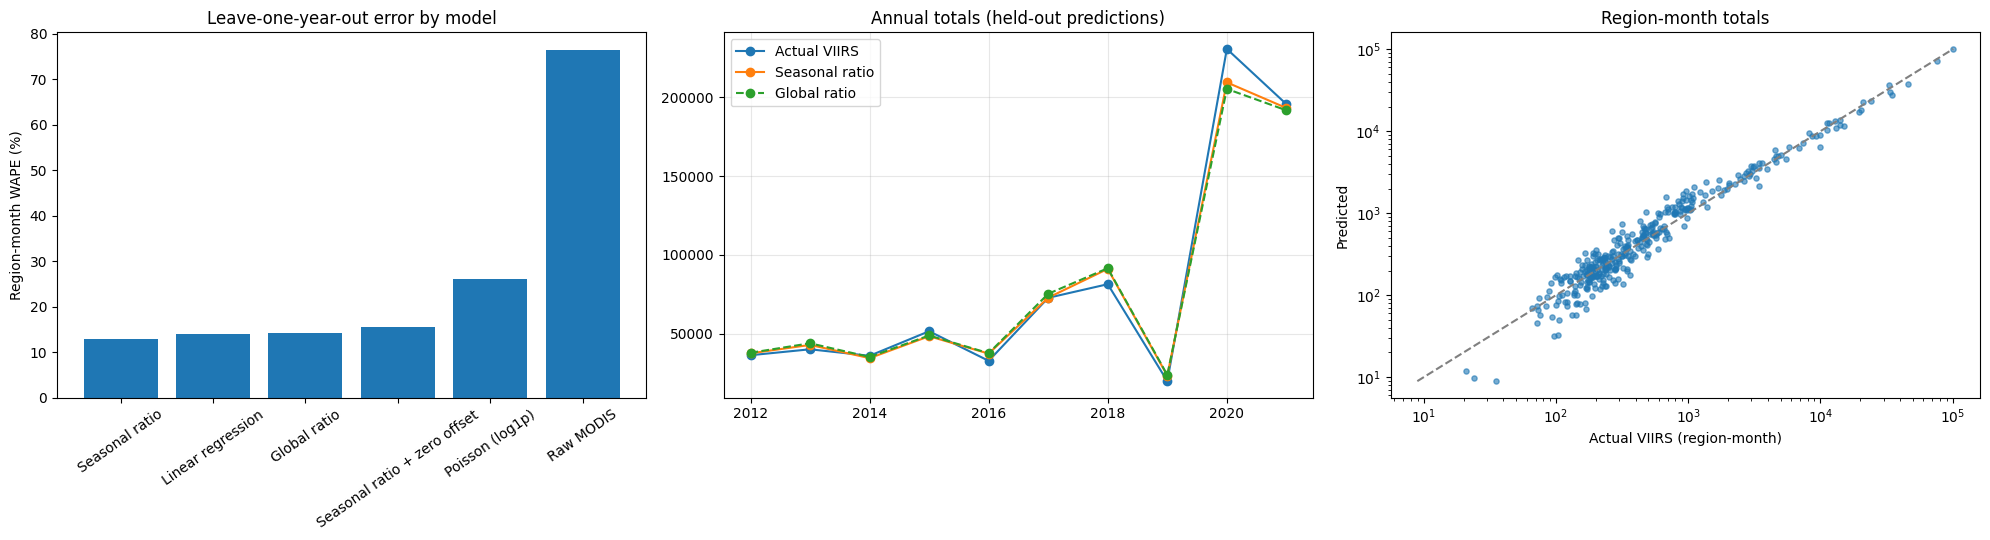

In [21]:
diag = pd.DataFrame({"year": YEAR, "season": panel["season"].to_numpy(), "region": panel["region"].to_numpy(),
                     "M": M, "V": V, "pred": cv_pred[selected], "global": cv_pred["Global ratio"]})

def bias_table(df, by):
    g = (df.groupby(by, observed=True)
         .agg(rows=("V", "size"), actual=("V", "sum"), predicted=("pred", "sum")).reset_index())
    g["bias_pct"] = (g["predicted"] - g["actual"]) / g["actual"] * 100
    return g

by_season = bias_table(diag, "season").set_index("season").loc[SEASONS].reset_index()
by_region = bias_table(diag, "region")
by_year = bias_table(diag, "year")
ne = diag[NONEMPTY].copy()
ne["modis_bin"] = pd.cut(ne["M"], bins=[-0.5, 0.5, 2, 10, 50, np.inf], labels=["0", "1-2", "3-10", "11-50", ">50"])
by_bin = bias_table(ne, "modis_bin")
for t in [by_season, by_region, by_bin]:
    display(t.round(2))

fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
ax[0].bar(cv_results["model"], cv_results["rm_WAPE"] * 100)
ax[0].set_ylabel("Region-month WAPE (%)"); ax[0].set_title("Leave-one-year-out error by model")
ax[0].tick_params(axis="x", rotation=35)
yt = diag.groupby("year")[["V", "pred", "global"]].sum()
ax[1].plot(yt.index, yt["V"], marker="o", label="Actual VIIRS")
ax[1].plot(yt.index, yt["pred"], marker="o", label=selected)
ax[1].plot(yt.index, yt["global"], marker="o", linestyle="--", label="Global ratio")
ax[1].set_title("Annual totals (held-out predictions)"); ax[1].legend(); ax[1].grid(alpha=0.3)
A = np.bincount(rm_key, weights=V, minlength=G); P = np.bincount(rm_key, weights=cv_pred[selected], minlength=G)
ok = A > 0
ax[2].scatter(A[ok], P[ok], s=14, alpha=0.6)
lim = [max(1, min(A[ok].min(), P[ok].min())), max(A.max(), P.max())]
ax[2].plot(lim, lim, "--", color="gray"); ax[2].set_xscale("log"); ax[2].set_yscale("log")
ax[2].set_xlabel("Actual VIIRS (region-month)"); ax[2].set_ylabel("Predicted"); ax[2].set_title("Region-month totals")
plt.tight_layout(); plt.savefig(REPORT_DIR / "phase5_diagnostics.png", dpi=250); plt.show()

In [22]:
final = {name: fit(core) for name, (fit, pred) in MODELS.items()}

b = pd.DataFrame({"year": YEAR, "season": panel["season"].to_numpy(), "V": V, "M": M,
                  "V_pos": np.where(M > 0, V, 0.0), "V_zero": np.where(M == 0, V, 0.0),
                  "n_zero": (M == 0).astype(float)})
T = np.stack([b.groupby(["year", "season"])[c].sum().unstack("season")[SEASONS].to_numpy()
              for c in ["V", "M", "V_pos", "V_zero", "n_zero"]], axis=-1)   # (years, seasons, 5)

rng = np.random.default_rng(42)
boot = []
for _ in range(2000):
    w = np.bincount(rng.integers(0, len(YEARS), len(YEARS)), minlength=len(YEARS))
    S = np.tensordot(w, T, axes=(0, 0))                       # (seasons, 5)
    boot.append([S[:, 0].sum() / S[:, 1].sum(), *(S[:, 2] / S[:, 1]), *(S[:, 3] / S[:, 4])])
names = ["global_ratio"] + [f"ratio_{s}" for s in SEASONS] + [f"offset_{s}" for s in SEASONS]
boot = np.array(boot)

point = [final["Global ratio"]["ratio"]] + [final["Seasonal ratio + zero offset"]["ratio"][s] for s in SEASONS] \
        + [final["Seasonal ratio + zero offset"]["offset"][s] for s in SEASONS]
ci = pd.DataFrame({"parameter": names, "estimate": point,
                   "p2.5": np.percentile(boot, 2.5, axis=0), "p50": np.percentile(boot, 50, axis=0),
                   "p97.5": np.percentile(boot, 97.5, axis=0)})
display(ci.round(4))
print("Seasonal ratio (all-rows) model:", {k: round(v, 3) for k, v in final["Seasonal ratio"]["ratio"].items()})

,parameter,estimate,p2.5,p50,p97.5
0,global_ratio,4.2546,3.9520,4.2350,4.4455
1,ratio_DJF,2.3828,1.7043,2.3719,3.1776
2,ratio_MAM,1.9417,1.7858,1.9383,2.1102
3,ratio_JJA,4.1695,3.9247,4.1600,4.4163
4,ratio_SON,4.3173,3.6163,4.2857,4.5569
5,offset_DJF,0.0742,0.0636,0.0738,0.0840
6,offset_MAM,0.0750,0.0668,0.0748,0.0838
7,offset_JJA,0.0756,0.0660,0.0753,0.0855
8,offset_SON,0.0895,0.0793,0.0891,0.1016


Seasonal ratio (all-rows) model: {'DJF': 3.315, 'JJA': 4.275, 'MAM': 3.175, 'SON': 4.476}


In [23]:
cv_results.to_csv(OUT_DIR / "cv_results.csv", index=False)
wape_by_year.to_csv(OUT_DIR / "cv_wape_by_year.csv")
fwd.to_csv(OUT_DIR / "forward_test_results.csv", index=False)
ci.to_csv(OUT_DIR / "ratio_bootstrap_ci.csv", index=False)
for n, t in [("season", by_season), ("region", by_region), ("year", by_year), ("modis_bin", by_bin)]:
    t.to_csv(OUT_DIR / f"selected_model_bias_by_{n}.csv", index=False)

cols = ["ix", "iy", "cell_id", "month", "year", "season", "region", "modis_all_n", "viirs_all_n"]
cvp = panel.loc[NONEMPTY, cols].copy()
for n in MODELS:
    cvp["pred_" + n.lower().replace(" ", "_").replace("+", "plus").replace("(", "").replace(")", "")] = cv_pred[n][NONEMPTY]
cvp.to_parquet(OUT_DIR / "cv_predictions_nonempty.parquet", index=False)

rm = pd.DataFrame({"region_month": rm_labels, "actual": np.bincount(rm_key, weights=V, minlength=G)})
for n in MODELS:
    rm[n] = np.bincount(rm_key, weights=cv_pred[n], minlength=G)
rm.to_csv(OUT_DIR / "cv_region_month.csv", index=False)

params = {
    "project": "PyroSync", "phase": 5, "selected_model": selected,
    "selection_rule": "simplest model within 5% of best leave-one-year-out region-month WAPE",
    "fit_period": f"{panel['month'].min().date()} to {panel['month'].max().date()}",
    "global_ratio": final["Global ratio"]["ratio"],
    "seasonal_ratio_all_rows": final["Seasonal ratio"]["ratio"],
    "seasonal_ratio_positive_modis": final["Seasonal ratio + zero offset"]["ratio"],
    "zero_modis_offset": final["Seasonal ratio + zero offset"]["offset"],
    "linear": {"intercept": float(final["Linear regression"]["est"].intercept_),
               "slope": float(final["Linear regression"]["est"].coef_[0])},
    "poisson_log1p": {"intercept": float(final["Poisson (log1p)"]["est"].intercept_),
                      "coef": float(final["Poisson (log1p)"]["est"].coef_[0])},
    "bootstrap_ci": ci.to_dict("records"),
}
with open(OUT_DIR / "final_model_parameters.json", "w") as f:
    json.dump(params, f, indent=4)
with open(OUT_DIR / "all_candidate_models.pkl", "wb") as f:
    pickle.dump({"selected": selected, "models": final}, f)
print("Saved", len(list(OUT_DIR.iterdir())), "files to", OUT_DIR)

Saved 12 files to /content/drive/MyDrive/Nasa App Challenges/PyroSync/data/harmonization/phase5


In [24]:
print("=" * 80); print("PYROSYNC — PHASE 5 FINAL REPORT"); print("=" * 80)
print(f"\nData: {len(panel):,} cell-months, {panel['month'].nunique()} months, {len(YEARS)} years")
print(f"Totals: MODIS {M.sum():,.0f} | VIIRS {V.sum():,.0f} | ratio {V.sum()/M.sum():.4f}")
print("\nLeave-one-year-out results:"); print(cv_results.round(3).to_string(index=False))
print(f"\nSelected: {selected}")
print("\nForward test (train <=2019, test 2020-21; diagnostic only):"); print(fwd.round(3).to_string(index=False))
print("\nSelected-model bias by season:"); print(by_season.round(2).to_string(index=False))
print("\nSelected-model bias by MODIS bin:"); print(by_bin.round(2).to_string(index=False))
print("\nParameter intervals (95%, year bootstrap):"); print(ci.round(4).to_string(index=False))
print("\nLimitations:")
for l in ["VIIRS is the statistical reference, not ground truth.",
          "Only California 2012-2021 data; ratios may not transfer to other regions.",
          "Ten years are few; the 2020-21 test period was previously examined (Phase 6 of the earlier run).",
          "Models estimate VIIRS-equivalent detection counts, not fire events or area.",
          "S-NPP VIIRS only; MODIS and VIIRS differ in resolution, overpass times and saturation."]:
    print("-", l)
print("\nPHASE 5 COMPLETED")

PYROSYNC — PHASE 5 FINAL REPORT

Data: 538,713 cell-months, 119 months, 10 years
Totals: MODIS 187,317 | VIIRS 796,962 | ratio 4.2546

Leave-one-year-out results:
                       model  rm_WAPE  total_bias_pct  cm_RMSE  cm_MAE  cm_bias  actual_total  predicted_total
              Seasonal ratio    0.129          -0.810   30.281   7.749   -0.185      796962.0       790507.708
           Linear regression    0.141           2.804   30.388   8.159    0.641      796962.0       819305.907
                Global ratio    0.143          -0.737   30.933   8.061   -0.168      796962.0       791091.961
Seasonal ratio + zero offset    0.155          -1.445   31.880   7.513   -1.467      796962.0       785449.589
             Poisson (log1p)    0.261           1.923   72.392  10.755   -2.901      796962.0       812286.432
                   Raw MODIS    0.765         -76.496  103.642  17.883  -17.498      796962.0       187317.000

Selected: Seasonal ratio

Forward test (train <=2019, test 

In [25]:
# 1. keep the old (zero-offset model) intervals under their own name, once
old_path, keep_path = OUT_DIR / "ratio_bootstrap_ci.csv", OUT_DIR / "ratio_bootstrap_ci_zero_offset_model.csv"
if not keep_path.exists():
    pd.read_csv(old_path).to_csv(keep_path, index=False)
old_ci = pd.read_csv(keep_path)

# 2. year-bootstrap of the SELECTED model: all-rows seasonal ratios (sum VIIRS / sum MODIS per season)
b = pd.DataFrame({"year": YEAR, "season": panel["season"].to_numpy(), "V": V, "M": M})
T = np.stack([b.groupby(["year", "season"])[c].sum().unstack("season")[SEASONS].to_numpy()
              for c in ["V", "M"]], axis=-1)                      # (years, seasons, 2)

rng = np.random.default_rng(42)
boot = []
for _ in range(2000):
    w = np.bincount(rng.integers(0, len(YEARS), len(YEARS)), minlength=len(YEARS))
    S = np.tensordot(w, T, axes=(0, 0))                           # (seasons, 2)
    boot.append([S[:, 0].sum() / S[:, 1].sum(), *(S[:, 0] / S[:, 1])])
boot = np.array(boot)

names = ["global_ratio"] + [f"ratio_{s}" for s in SEASONS]
point = [final["Global ratio"]["ratio"]] + [final["Seasonal ratio"]["ratio"][s] for s in SEASONS]
ci_sel = pd.DataFrame({"parameter": names, "estimate": point,
                       "p2.5": np.percentile(boot, 2.5, axis=0), "p50": np.percentile(boot, 50, axis=0),
                       "p97.5": np.percentile(boot, 97.5, axis=0)})

# 3. check against the saved parameters, then overwrite
saved = json.load(open(OUT_DIR / "final_model_parameters.json"))
for s in SEASONS:
    assert abs(final["Seasonal ratio"]["ratio"][s] - saved["seasonal_ratio_all_rows"][s]) < 1e-9
ci_sel.to_csv(old_path, index=False)
saved["bootstrap_ci"] = ci_sel.to_dict("records")                       # selected model
saved["bootstrap_ci_zero_offset_model"] = old_ci.to_dict("records")     # not the selected model
with open(OUT_DIR / "final_model_parameters.json", "w") as f:
    json.dump(saved, f, indent=4)

display(ci_sel.round(4))

,parameter,estimate,p2.5,p50,p97.5
0,global_ratio,4.2546,3.9520,4.2350,4.4455
1,ratio_DJF,3.3149,2.8330,3.2996,3.8405
2,ratio_MAM,3.1748,3.0150,3.1817,3.3777
3,ratio_JJA,4.2747,4.0491,4.2655,4.5506
4,ratio_SON,4.4756,3.9588,4.4552,4.6548


In [26]:
expected = {"cv_results.csv", "cv_wape_by_year.csv", "forward_test_results.csv", "ratio_bootstrap_ci.csv",
            "ratio_bootstrap_ci_zero_offset_model.csv", "selected_model_bias_by_season.csv",
            "selected_model_bias_by_region.csv", "selected_model_bias_by_year.csv",
            "selected_model_bias_by_modis_bin.csv", "cv_predictions_nonempty.parquet",
            "cv_region_month.csv", "final_model_parameters.json", "all_candidate_models.pkl"}
rows = [(f.name, round(f.stat().st_size / 1e6, 2), pd.Timestamp(f.stat().st_mtime, unit="s").strftime("%Y-%m-%d %H:%M"))
        for f in sorted(OUT_DIR.iterdir()) if f.name not in expected]
print(f"{len(list(OUT_DIR.iterdir()))} files in folder; {len(rows)} not written by this Phase 5:")
print(pd.DataFrame(rows, columns=["file", "MB", "modified"]).to_string(index=False))
missing = expected - {f.name for f in OUT_DIR.iterdir()}
assert not missing, missing

13 files in folder; 0 not written by this Phase 5:
Empty DataFrame
Columns: [file, MB, modified]
Index: []
